## What is a random forest?

**1. One tree is unstable (high variance).** A deep tree fits every training row, noise included. If a few rows change, the first split can change, and with it the whole tree and its predictions.

**2. An ensemble combines many models.** In regression it averages their predictions; in classification they vote. Averaging only helps when the models make **different** errors, so the errors cancel out. With a true value of 3.0:

| | Tree A | Tree B | Tree C | Tree D | **Average** |
|---|---|---|---|---|---|
| Different errors | 3.5 | 2.6 | 3.1 | 2.8 | **3.0** ✅ |
| Same errors | 3.5 | 3.5 | 3.5 | 3.5 | **3.5** ❌ |

Ten copies of the same tree are no better than one tree.

**3. A random forest makes its trees different on purpose:**
- each tree is trained on a random sample of the rows, drawn with replacement (*bootstrapping*);
- at each split, a tree may only consider a random subset of the columns (otherwise every tree would split on `MedInc` first and they would all look alike).

**In short:** each tree overfits in its own way, and averaging many different trees cancels much of that noise. The result is a steadier prediction than any single tree.

In [13]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

rng = np.random.default_rng(seed=42)
years = rng.uniform(0, 12, size=140).round(2)
salary = 22_000 + 2_600 * years + rng.normal(0, 4_000, size=140)
salaries = pd.DataFrame({"YearsExperience": years, "Salary": salary.round(-2)})

X = salaries[["YearsExperience"]]
y = salaries["Salary"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## Bootstrap sample

A **bootstrap sample** is a new training set built by picking rows from the original one **at random, with replacement**, until it has the **same number of rows** as the original.

"With replacement" means a row is put back after it's picked, so it can be picked again. Example with 5 rows:

| | Rows picked |
|---|---|
| Original | 0, 1, 2, 3, 4 |
| Bootstrap sample 1 | 3, 0, 3, 4, 1 |
| Bootstrap sample 2 | 2, 2, 4, 0, 2 |

Each sample has 5 rows, but some rows are repeated (3 twice, 2 three times) and some are missing (2 is missing from sample 1; 1 and 3 from sample 2).

**How many different rows does a sample use?** On average about **63%** of the original rows. The other ~37% are left out, and are called *out-of-bag* rows. The cell below checks it: `0.634`.

Where does 63% come from? In each pick, a given row has a 1/n chance of being chosen, so the chance it is never chosen in n picks is (1 − 1/n)ⁿ ≈ 1/e ≈ 0.37 when n is large. That makes 1 − 0.37 ≈ 0.63 of the rows used.

**Why it's useful:** each bootstrap sample is a slightly different version of the same data. A tree trained on each one comes out different, which is what a random forest needs for the errors to cancel out when averaging.

In code, `rng.integers(0, len(X_train), size=len(X_train))` draws random row numbers with replacement, and `X_train.iloc[positions]` takes those rows.

In [14]:
rng = np.random.default_rng(0)
bootstrap_positions = rng.integers(0, len(X_train), size=len(X_train))
len(np.unique(bootstrap_positions)) / len(X_train)

0.6339285714285714

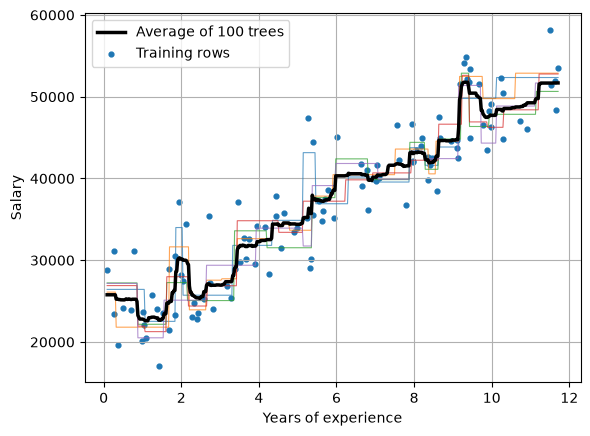

In [15]:
from sklearn.tree import DecisionTreeRegressor

grid = pd.DataFrame(
    {"YearsExperience": np.linspace(X_train.min(), X_train.max(), num=500).ravel()}
)
tree_predictions = []
for seed in range(100):
    positions = np.random.default_rng(seed).integers(0, len(X_train), size=len(X_train))
    tree = DecisionTreeRegressor(min_samples_leaf=5, random_state=seed).fit(
        X_train.iloc[positions], y_train.iloc[positions]
    )
    tree_predictions.append(tree.predict(grid))
    if seed < 5:
        plt.plot(grid, tree_predictions[-1], linewidth=0.8, alpha=0.7)

plt.plot(
    grid,
    np.mean(tree_predictions, axis=0),
    color="black",
    linewidth=2.5,
    label="Average of 100 trees",
)
plt.scatter(X_train, y_train, color="tab:blue", s=12, label="Training rows")
plt.xlabel("Years of experience")
plt.ylabel("Salary")
plt.legend()
plt.grid(True)
plt.show()

### What the chart shows

We train 100 trees, each on a different bootstrap sample of the training rows, so each tree is different. All of them predict the same 500 evenly spaced points (`grid`), which lets us draw each tree as a line.

- **Thin lines:** the first 5 trees. Each one is jumpy and different from the others (high variance).
- **Black line:** the average of the 100 trees, which is the random forest. It is much smoother because the trees' errors cancel out.
- **Dots:** the training rows, for reference.

The chart doesn't measure error, since the grid points have no real salaries. It only shows that one tree is unstable and the average is steady. To get a number, compare the test MAE of a single tree with the test MAE of the forest.

In [18]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

models = {
    "Linear regression": LinearRegression(),
    "Unlimited tree": DecisionTreeRegressor(random_state=42),
    "Tree of depth 2": DecisionTreeRegressor(max_depth=2, random_state=42),
    "Random forest": RandomForestRegressor(n_estimators=200, random_state=42),
    "Random forest, leaves of 5 or more": RandomForestRegressor(
        n_estimators=200, min_samples_leaf=5, random_state=42
    ),
}
pd.DataFrame(
    {
        name: {
            "Training MAE": mean_absolute_error(
                y_train, model.fit(X_train, y_train).predict(X_train)
            ),
            "Test MAE": mean_absolute_error(y_test, model.predict(X_test)),
        }
        for name, model in models.items()
    }
).T.round()

,Training MAE,Test MAE
Linear regression,3147.0,3647.0
Unlimited tree,190.0,4675.0
Tree of depth 2,3179.0,4277.0
Random forest,1432.0,4300.0
"Random forest, leaves of 5 or more",2583.0,3928.0


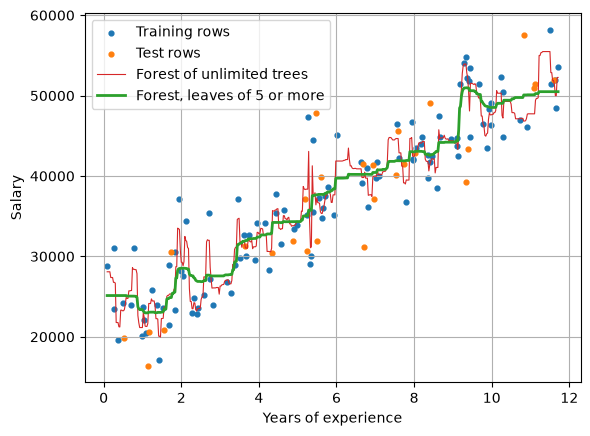

In [20]:
plt.scatter(X_train, y_train, color='tab:blue', s=12, label='Training rows')
plt.scatter(X_test, y_test, color='tab:orange', s=12, label= 'Test rows')
plt.plot(grid, models['Random forest'].predict(grid), color='tab:red', linewidth=0.8, label='Forest of unlimited trees' )
plt.plot(grid, models['Random forest, leaves of 5 or more'].predict(grid), color='tab:green', linewidth= 2, label='Forest, leaves of 5 or more' )
plt.xlabel('Years of experience')
plt.ylabel('Salary')
plt.legend()
plt.grid(True)
plt.show()

Now in this examples we can visualize that, a tree isnt the best way to predict that for a linea regression problem
With all of that, we can see that we must limitate the number of leaves to avoid picking trees out of bounds that
make the model less accurate

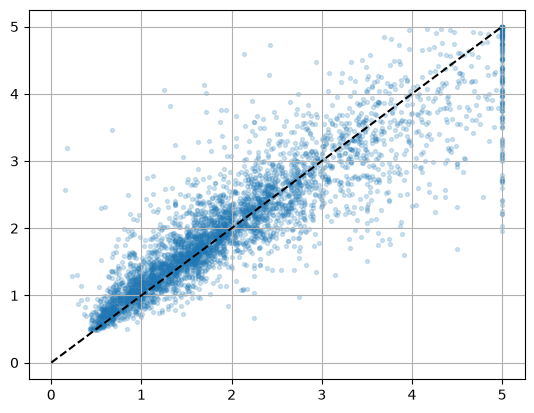

In [25]:
from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing(as_frame= True).frame
X_housing = housing.drop(columns='MedHouseVal')
y_housing = housing['MedHouseVal']
X_housing_train, X_housing_test, y_housing_train, y_housing_test = train_test_split(X_housing, y_housing, test_size=0.2, random_state=42)

housing_forest = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1).fit(X_housing_train, y_housing_train)

plt.scatter(y_housing_test, housing_forest.predict(X_housing_test), alpha=0.2, s=8) 
plt.plot([0,5], [0,5], 'k--')
plt.grid(True)
plt.show()

Which features matter

In [26]:
from sklearn.inspection import permutation_importance

permutation = permutation_importance(housing_forest, X_housing_test, y_housing_test, n_repeats=5, random_state=42, n_jobs=-1)
pd.DataFrame({
    'impurity importance': housing_forest.feature_importances_,
    'permutation importance': permutation.importances_mean,
    }, index=X_housing.columns).sort_values('permutation importance', ascending=False).round(3)

,impurity importance,permutation importance
MedInc,0.525,0.731
Latitude,0.089,0.440
Longitude,0.088,0.335
AveOccup,0.138,0.202
HouseAge,0.055,0.070
AveRooms,0.044,0.029
AveBedrms,0.030,0.009
Population,0.031,0.008


### Impurity importance vs permutation importance

Both answer **"which columns does the model rely on?"**, but they measure it differently.

#### Impurity importance (`feature_importances_`)

How much each column helped **build** the trees, measured on the **training** data. Every split reduces the error (the "impurity") of the groups it creates. The reductions are added up per column and scaled to **sum to 1**.

It counts how much a column helped, not how many splits used it. Example: one tree removes 100 units of error in total:

| Split | Column | Error removed |
|---|---|---|
| Top split | MedInc | 60 |
| 2nd level | Latitude | 25 |
| 10 tiny splits at the bottom | AveOccup | 15 (in total) |

AveOccup was used in 10 splits and MedInc in only 1, but MedInc gets 60/100 = **0.60** and AveOccup **0.15**.

- MedInc = 0.525 in our table means 52.5% of all the error removed by the forest came from MedInc splits.
- It is free (computed during `fit`), but it favors continuous columns with many values, which have more possible cut points.

#### Permutation importance (`permutation_importance`)

How much **worse** the model gets on the **test** data when one column is **shuffled**. Shuffling keeps realistic values but breaks the link between that column and the price.

1. Measure the model normally: test R² = **0.805**.
2. Shuffle MedInc, so each district gets the income of another random district:

| District | MedInc real | MedInc shuffled | True price | Prediction (real) | Prediction (shuffled) |
|---|---|---|---|---|---|
| 0 | 1.68 | 5.63 | 0.48 | 0.51 ✅ | 1.98 ❌ |
| 1 | 2.53 | 6.84 | 0.46 | 0.75 | 3.77 ❌ |
| 2 | 3.48 | 1.72 | 5.00 | 4.96 ✅ | 3.55 ❌ |
| 3 | 5.74 | 6.47 | 2.19 | 2.50 | 2.80 |

3. Measure again: test R² = **0.073**. The drop, 0.805 − 0.073 ≈ **0.73**, is MedInc's importance. The model needs it.

The same with Population: R² goes from 0.805 to 0.796, a drop of about **0.01**. The model barely uses it.

Values are drops in R², so they **don't sum to 1**. It works with any model.

#### Example with vehicles

Importance always depends on the target:
- Predicting **number of wheels**: `type = motorbike?` separates everything in one split, so `type` ≈ 1 and `cc` ≈ 0. Shuffle `type` and the model gives 4 wheels to motorbikes.
- Predicting **fuel consumption**: `cc` may matter more than `type`, because cars with different engine sizes use very different amounts.

#### Reading our table

| | Impurity | Permutation | Interpretation |
|---|---|---|---|
| MedInc | 0.525 | 0.731 | Most important in both. Clear winner. |
| Latitude / Longitude | 0.089 / 0.088 | 0.440 / 0.335 | Small in impurity, **big** in permutation: each split alone helps a little, but together they give the location, and breaking either one hurts the model a lot. |
| AveOccup | 0.138 | 0.202 | 2nd in impurity, only 4th in permutation: a continuous column with outliers, used often in training but less useful on test data. |
| AveBedrms, Population | 0.030 / 0.031 | 0.009 / 0.008 | Almost useless in both. |

Neither measure says what **causes** the price, only what the **model** uses.

How many trees

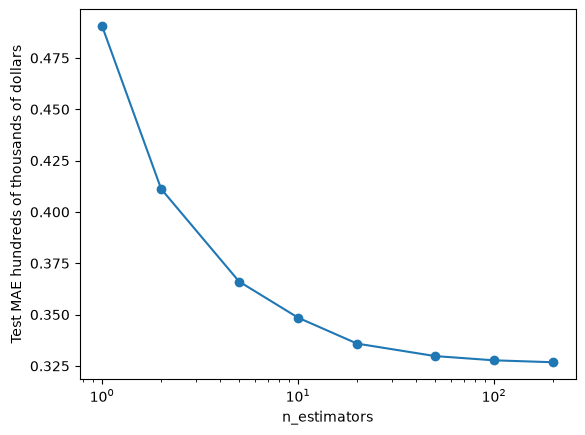

In [28]:

tree_counts = [1, 2, 5, 10, 20, 50, 100, 200]

errors_by_count = pd.Series({
    count: mean_absolute_error(
            y_housing_test, 
            RandomForestRegressor(n_estimators=count, random_state=42, n_jobs=-1).fit(X_housing_train, y_housing_train).predict(X_housing_test))
        for count in tree_counts
    }).rename_axis('n_estimators')
errors_by_count.plot(marker='o', logx=True)
plt.ylabel('Test MAE hundreds of thousands of dollars')
plt.show()

Settings
| Setting | Meaning | Default in scikit-learn | Effect |
|---|---|---|---|
|n_estimators| Number of trees| 100| More is never much worse, only slower; the gain flattens out|
|max_features|Features each split may choose among|All for regresion, squareroot(number of features) for classification| Fewer make the trees more different from one another, and each tree weaker|
|max_depth, min_samples_leaf|Limits on each tree|none: trees grow until their leaves are pure| Smooother perdictions: useful with noisy data|
|n_jobs| Processor cores used|1|-1 uses all of them: trees are trained independently|
|random_state|Seed of the boostraps and the feature subsests|none|Fixes the result, to reproduce it|
Strengths and limits
- Strong with almost no tuning.
- Little preparation
- Parallel
- Harder to read than one tree
- Larger and slower to predict
- No extrapolitation